Dataset shape: (440, 8)

First five rows:
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185

Feature matrix shape: (440, 6)

K-Means evaluation:
 k   Inertia  Silhouette Score  Davies-Bouldin Index
 2 1844.0641            0.2903                1.3515
 3 1553.4213            0.2594                1.3406
 4 1386.8627            0.1885                1.5408
 5 1266.1494            0.1916                1.4843
 6 1174.7586            0.2009                1.4323
 7 1086.3587            0.1958                1.3919
 8 1028.4862            0.1852                1.4408

Select

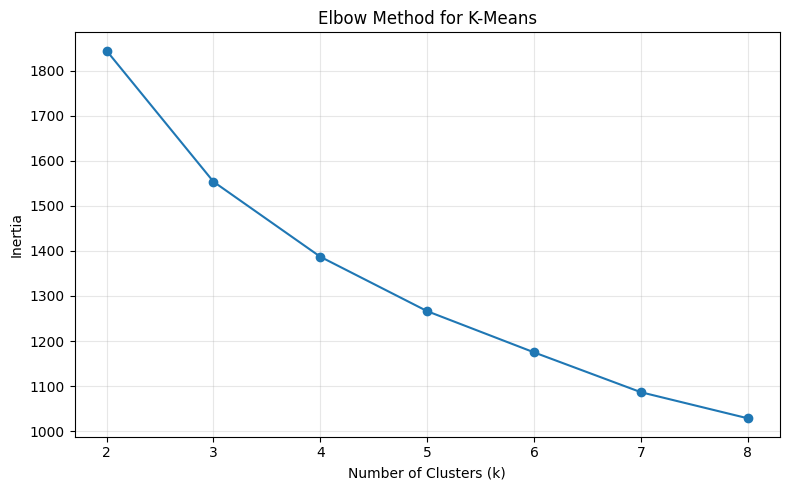

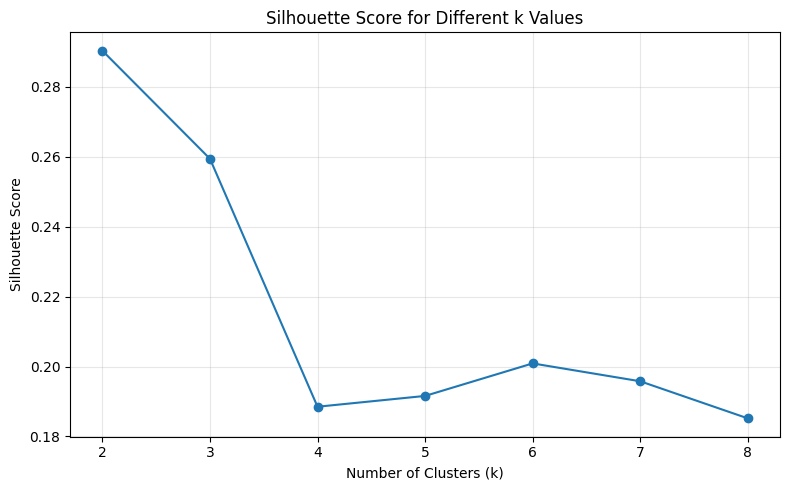

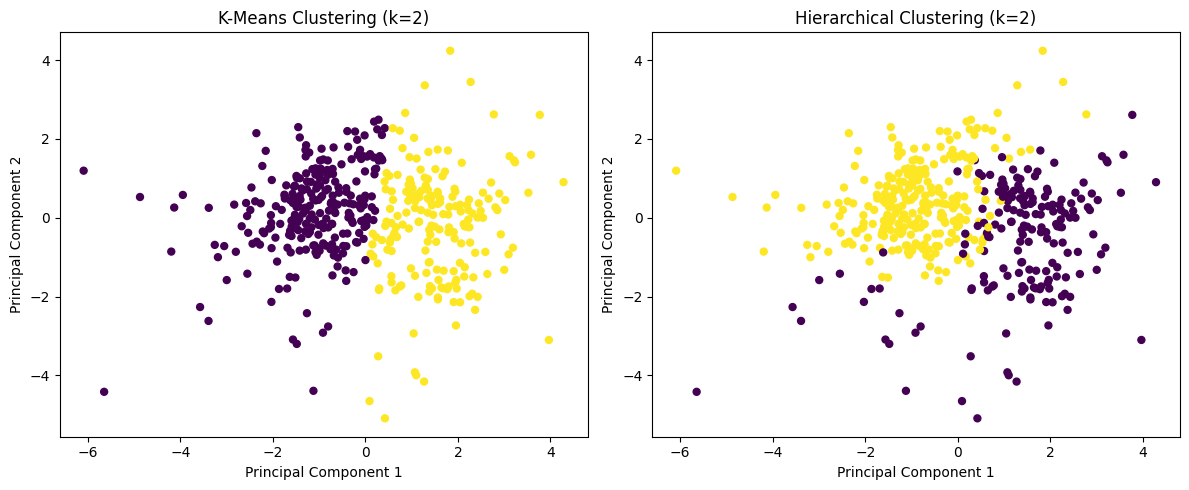


PCA explained variance ratio: [0.44077752 0.27194917]

Generated files:
elbow_method.png
silhouette_scores.png
cluster_visualization.png
kmeans_metrics_by_k.csv
algorithm_comparison.csv
cluster_profiles.csv
customers_with_cluster_labels.csv

Clustering assignment completed successfully.


In [2]:

# Practical Assignment 6: Clustering Algorithms
# Dataset: UCI Wholesale Customers

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

# 1. Load the real-world dataset
DATA_URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00292/Wholesale%20customers%20data.csv"
)

# FIX: The CSV already has column headers
df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# 2. Select six annual spending features
features = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicassen"
]

X = df[features].apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median())

# Log transformation and feature scaling
X_log = np.log1p(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("\nFeature matrix shape:", X_scaled.shape)

# 3. Evaluate K-Means for k = 2 to 8
k_values = range(2, 9)
inertias = []
silhouette_scores = []
db_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

metrics_by_k = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores,
    "Davies-Bouldin Index": db_scores
})

print("\nK-Means evaluation:")
print(metrics_by_k.round(4).to_string(index=False))

# Select k with the highest silhouette score
best_k = list(k_values)[int(np.argmax(silhouette_scores))]
print("\nSelected number of clusters:", best_k)

# 4. Fit K-Means
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# 5. Fit Hierarchical Clustering
hierarchical = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# 6. Compare algorithms
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical Clustering"],
    "Silhouette Score": [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_scaled, hierarchical_labels)
    ],
    "Davies-Bouldin Index": [
        davies_bouldin_score(X_scaled, kmeans_labels),
        davies_bouldin_score(X_scaled, hierarchical_labels)
    ]
})

print("\nAlgorithm comparison:")
print(comparison.round(4).to_string(index=False))

# 7. Cluster sizes
print("\nK-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

# 8. Average annual spending per cluster
cluster_profile = X.copy()
cluster_profile["Cluster"] = kmeans_labels
cluster_profile = cluster_profile.groupby("Cluster")[features].mean()

print("\nMean spending per K-Means cluster:")
print(cluster_profile.round(2).to_string())

# 9. Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("elbow_method.png", dpi=300)
plt.show()

# 10. Silhouette Score graph
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different k Values")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("silhouette_scores.png", dpi=300)
plt.show()

# 11. PCA-based cluster visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=kmeans_labels, cmap="viridis", s=25
)
axes[0].set_title(f"K-Means Clustering (k={best_k})")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=hierarchical_labels, cmap="viridis", s=25
)
axes[1].set_title(f"Hierarchical Clustering (k={best_k})")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.savefig("cluster_visualization.png", dpi=300)
plt.show()

print("\nPCA explained variance ratio:", pca.explained_variance_ratio_)

# 12. Save metrics and cluster labels
metrics_by_k.to_csv("kmeans_metrics_by_k.csv", index=False)
comparison.to_csv("algorithm_comparison.csv", index=False)
cluster_profile.to_csv("cluster_profiles.csv")

df_output = df.copy()
df_output["KMeans_Cluster"] = kmeans_labels
df_output["Hierarchical_Cluster"] = hierarchical_labels
df_output.to_csv("customers_with_cluster_labels.csv", index=False)

print("\nGenerated files:")
print("elbow_method.png")
print("silhouette_scores.png")
print("cluster_visualization.png")
print("kmeans_metrics_by_k.csv")
print("algorithm_comparison.csv")
print("cluster_profiles.csv")
print("customers_with_cluster_labels.csv")

print("\nClustering assignment completed successfully.")
